# Week 5 - Principle Components

## Import libraries, write and load the data

In [20]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    'Revenue': [12450, 8945, 9305, 15525, 12650, 7250, 10720, 17425, 16805, 11350, 
                9850, 15120, 16885, 15505, 17890, 14565, 16230, 13055, 15315, 13525, 
                14230, 10975, 17720, 15215, 10045, 17465, 11270, 13600, 17770, 17315, 
                15155, 10070, 16255, 15030, 12960, 15260, 11020, 12320, 16560, 15970, 
                15190, 13545, 15620, 16990, 14440, 14740, 16860, 11130, 16505, 14955],
    'COGS': [7490, 5650, 6105, 9560, 7905, 4200, 6750, 10505, 10455, 7250, 
              6500, 9200, 10370, 9495, 11150, 9060, 9900, 8190, 9450, 8500, 
              8910, 7050, 11000, 9395, 6500, 10475, 7070, 8395, 11125, 10550, 
              9325, 6350, 9990, 9195, 8105, 9380, 6805, 7625, 10205, 9870, 
              9270, 8335, 9635, 10375, 8820, 8880, 10380, 7020, 10110, 9195],
    'Marketing Spend': [1250, 1450, 1105, 1205, 850, 1525, 870, 1220, 1250, 1050, 
                        950, 1200, 1235, 1095, 1105, 1080, 1175, 1100, 1150, 1025, 
                        1100, 1095, 1220, 1105, 1100, 1220, 1020, 1050, 1155, 1215, 
                        1135, 1085, 1120, 1105, 1090, 1100, 1050, 1205, 1230, 1155, 
                        1220, 1050, 1205, 1220, 1020, 1100, 1150, 1020, 1120, 1105],
    'Administration Costs': [1950, 1745, 2095, 2450, 2895, 1525, 3100, 2700, 3100, 3050, 
                             2400, 2720, 3280, 2910, 3225, 3425, 3155, 2765, 3715, 3000, 
                             3220, 2830, 3500, 3715, 2445, 3770, 3180, 3155, 3490, 3550, 
                             3190, 2635, 3445, 3730, 3465, 3720, 3345, 2695, 3625, 3955, 
                             3480, 3520, 3815, 3295, 3620, 3720, 3540, 3090, 3650, 3795],
    'Profit': [1760, 1100, 1000, 2310, 1000, 1000, 1000, 2000, 2000, 1000, 
               1000, 2000, 2000, 2000, 2410, 1000, 2000, 2000, 2000, 2000, 
               2000, 1000, 2000, 1000, 1000, 2000, 1000, 2000, 2000, 1000, 
               1000, 1000, 2000, 1000, 1000, 2000, 1820, 2000, 1500, 1000, 
               2000, 2000, 1000, 2000, 2000, 1740, 2000, 2000, 1825, 1965]
}

df = pd.DataFrame(data)

df.head()

,Revenue,COGS,Marketing Spend,Administration Costs,Profit
0,12450,7490,1250,1950,1760
1,8945,5650,1450,1745,1100
2,9305,6105,1105,2095,1000
3,15525,9560,1205,2450,2310
4,12650,7905,850,2895,1000


### Standardize the features to have `mean=0` and `variance=1`


In [4]:
features = ['Revenue', 'COGS', 'Marketing Spend', 'Administration Costs', 'Profit']
x = df.loc[:, features].values
x = StandardScaler().fit_transform(x)

### Run PCA

In [8]:
# Run PCA
pca = PCA(n_components=2)
principalComponents = pca.fit_transform(x)

# Create a DataFrame with the two components
principalDf = pd.DataFrame(data = principalComponents, columns = ['PC1', 'PC2'])

principalDf.head()


,PC1,PC2
0,1.654457,1.847138
1,3.714677,2.855677
2,3.310663,0.035549
3,-0.572898,1.632961
4,1.325975,-2.316009


### Standard deviation and variance of each principle component

In [19]:
# Standard deviation of each component
std_dev = np.sqrt(pca.explained_variance_)

# Variance of each component
variance = pca.explained_variance_

# Percentage of variance explained by each component
variance_ratio = pca.explained_variance_ratio_

# Convert to DataFrame for clearer visualization
df_pca = pd.DataFrame({'stdev': std_dev, 
                       'variance': variance, 
                       '% of variance': variance_ratio},
                       index=[f'PC{i+1}' for i in range(std_dev.shape[0])])

# Convert "Percentage of Variance" to a percentage
df_pca['% of variance'] = df_pca['% of variance'].map(lambda x: round(x*100, 2))

df_pca

,stdev,variance,% of variance
PC1,1.710468,2.925700,57.34
PC2,1.119837,1.254035,24.58


### Significance of each variable to the principal components

In [16]:
# Create a dataframe of the PCA components
df_components = pd.DataFrame(pca.components_, columns=df.columns)

# Transpose it, so that variables are the index and PCs are the columns
df_components = df_components.T

# Give the columns meaningful names
df_components.columns = [f'PC{i+1}' for i in range(df_components.shape[1])]

# Show the dataframe
df_components

,PC1,PC2
Revenue,-0.575125,0.074757
COGS,-0.574206,0.042795
Marketing Spend,-0.015125,0.821365
Administration Costs,-0.449516,-0.453776
Profit,-0.370439,0.334705


### Plot the two components

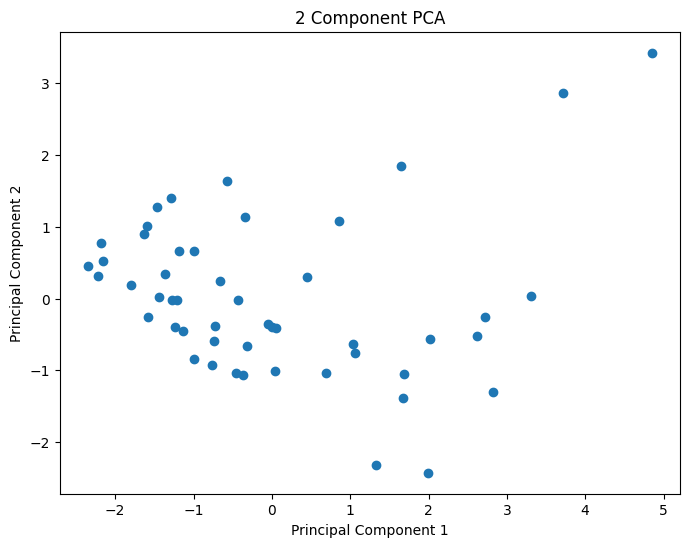

In [9]:
plt.figure(figsize=(8,6))
plt.scatter(principalDf['PC1'], principalDf['PC2'])
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('2 Component PCA')
plt.show()

### A more complex example

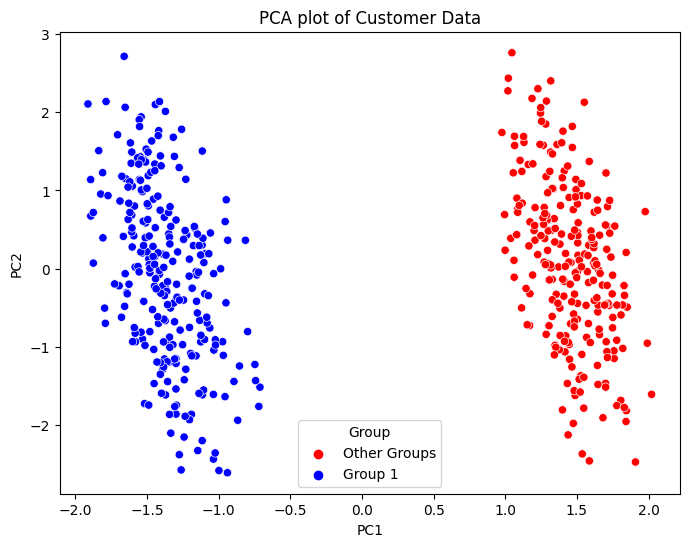

In [ ]:
# Randomly generate a 500*10 dataframe for customer features
np.random.seed(0)
df = pd.DataFrame(np.random.rand(500, 10)*100,
                  columns=[f'Feature{i+1}' for i in range(10)])

# Assume last two columns are features that distinct two groups
df['Feature9'] = df['Feature9'] + np.where(df['Feature10']>50, 400, 0)
df['Feature10'] = df['Feature10'] + np.where(df['Feature10']>50, 500, 0)

# Normalize the data
scaler = StandardScaler()
df_normalized = scaler.fit_transform(df)

# Perform PCA
pca = PCA(n_components=5)
pca_result = pca.fit_transform(df_normalized)

# Convert the principal components to a DataFrame
principal_df = pd.DataFrame(data=pca_result, columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5'])

# Add a column to label the group of each customer based on their feature 10 value
principal_df['Group'] = ['Group 1' if i > 50 else 'Other Groups' for i in df['Feature10']]

# Plot
plt.figure(figsize=(8,6))
sns.scatterplot(x='PC1', y='PC2', hue='Group', data=principal_df, palette=['red', 'blue'])
plt.title('PCA plot of Customer Data')
plt.show()


In [24]:
# Standard deviation of each component
std_dev = np.sqrt(pca.explained_variance_)

# Variance of each component
variance = pca.explained_variance_

# Percentage of variance explained by each component
variance_ratio = pca.explained_variance_ratio_

# Convert to DataFrame for clearer visualization
df_pca = pd.DataFrame({'stdev': std_dev, 
                       'variance': variance, 
                       '% of variance': variance_ratio},
                       index=[f'PC{i+1}' for i in range(std_dev.shape[0])])

# Convert "Percentage of Variance" to a percentage
df_pca['% of variance'] = df_pca['% of variance'].map(lambda x: round(x*100, 2))

print(df_pca)


        stdev  variance  % of variance
PC1  1.428773  2.041392          20.37
PC2  1.082370  1.171525          11.69
PC3  1.074075  1.153636          11.51
PC4  1.054639  1.112264          11.10
PC5  1.015859  1.031970          10.30


In [26]:
# Create a dataframe of the PCA components
df_components = pd.DataFrame(pca.components_, columns=df.columns)

# Transpose it, so that variables are the index and PCs are the columns
df_components = df_components.T

# Give the columns meaningful names
df_components.columns = [f'PC{i+1}' for i in range(df_components.shape[1])]

# Show the dataframe
print(df_components)

                PC1       PC2       PC3       PC4       PC5
Feature1   0.064214 -0.207061 -0.223137  0.143482  0.784645
Feature2   0.072134 -0.193935  0.236656 -0.491586  0.287406
Feature3   0.073667  0.095341 -0.186789  0.710180  0.120295
Feature4  -0.037196 -0.453687  0.406998  0.193785 -0.294931
Feature5   0.054088 -0.369362 -0.390727  0.049901 -0.395604
Feature6   0.132335 -0.600487  0.266178  0.041189  0.166404
Feature7  -0.096614 -0.039097  0.445123  0.436491  0.027985
Feature8  -0.012847  0.441048  0.517683  0.029705  0.084895
Feature9  -0.690068 -0.079783 -0.041138 -0.011939  0.060791
Feature10 -0.691181 -0.071853 -0.048226 -0.010564  0.066304


### 3D scatterplot of PCA

In [31]:

from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot for the first three principal components
sc = ax.scatter(transformed_data['PC1'], transformed_data['PC2'], transformed_data['PC3'], 
                c=labels, cmap='viridis', s=60)

# Adding labels
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')

# Adding a color bar
plt.colorbar(sc)

# Show the plot
plt.show()



KeyboardInterrupt: 

/var/folders/dj/xzcqktn12vs76sjd8mjhv1yh0000gn/T/ipykernel_39488/595537954.py:18: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(principal_df['PC1'], principal_df['PC2'], principal_df['PC3'], c=colors, cmap="RdBu")


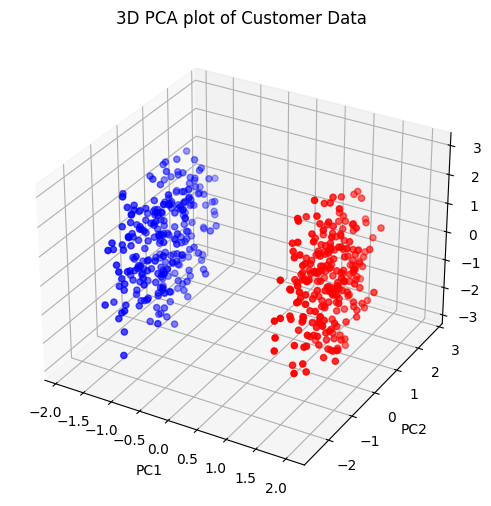

In [33]:
from mpl_toolkits.mplot3d import Axes3D

# Perform PCA with 3 components
pca = PCA(n_components=3)
pca_result = pca.fit_transform(df_normalized)

# Convert the principal components to a DataFrame
principal_df = pd.DataFrame(data=pca_result, columns=['PC1', 'PC2', 'PC3'])

# Add a column to label the group of each customer based on their feature 10 value
principal_df['Group'] = ['Group 1' if i > 50 else 'Other Groups' for i in df['Feature10']]

# Create a 3D plot
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

colors = ['blue' if label == 'Group 1' else 'red' for label in principal_df['Group']]
ax.scatter(principal_df['PC1'], principal_df['PC2'], principal_df['PC3'], c=colors, cmap="RdBu")

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
plt.title('3D PCA plot of Customer Data')
plt.show()